# California Housing Price Prediction
## OLS, Ridge (L2), and Lasso (L1) Regression — Task 2

This notebook predicts California census-block-group median house values from the supplied `housing.csv`. It follows the task brief: explore data, impute missing values, engineer interaction features, inspect multicollinearity, standardize numeric features, encode categorical features, tune Ridge/Lasso with `GridSearchCV`, and compare OLS, Ridge, and Lasso using RMSE, MAE, R², and residual analysis.

**Dataset-specific facts:** 20,640 records; 10 original columns; `median_house_value` is the target; `ocean_proximity` is categorical with five categories; `total_bedrooms` has 207 missing values. The maximum target is `$500,001` and 965 rows take exactly that value (about 4.68%), a ceiling that limits interpretation at the high end.

**Recommended modelling tools:** Python, scikit-learn `LinearRegression`, `Ridge`, `Lasso`, and `GridSearchCV`. Pandas and NumPy are used to read and calculate features from the CSV; Matplotlib is used for the requested plots. No alternative modelling framework is used.

In [1]:
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "data").exists():
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT / "src"))

from housing_price_pipeline import TARGET, load_dataset, engineer_features, get_feature_columns, run_experiment

DATA_PATH = REPO_ROOT / "data" / "housing.csv"
OUTPUT_DIR = REPO_ROOT / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE, TEST_SIZE, CV_FOLDS = 42, 0.20, 3

plt.rcParams.update({"figure.figsize": (10, 6), "axes.titlesize": 13,
                     "axes.labelsize": 11, "font.size": 10, "figure.dpi": 110})
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

def save_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("Repository:", REPO_ROOT)
print("Dataset:", DATA_PATH)

Repository: /Users/subhankarbiswas/Datheon_Machine_Learning_&_Data_Science_Internship/california-housing-ridge-lasso
Dataset: /Users/subhankarbiswas/Datheon_Machine_Learning_&_Data_Science_Internship/california-housing-ridge-lasso/data/housing.csv


## 1. Problem framing and dataset schema

Each row represents a California census block group. The target `median_house_value` is continuous, making this a supervised regression problem. The supplied CSV contains location, housing-stock totals, population/household counts, median income, and ocean proximity.

| Field | Meaning | Role |
|---|---|---|
| longitude, latitude | Geographic coordinates | Predictor |
| housing_median_age | Median housing age | Predictor |
| total_rooms, total_bedrooms | Aggregate counts | Predictors |
| population, households | Aggregate counts | Predictors |
| median_income | Median income in dataset units | Predictor |
| ocean_proximity | Proximity category | Categorical predictor |
| median_house_value | Median house value | Target |

The data describes block groups, not individual property listings. Model predictions are block-group estimates and should not be interpreted as property appraisals.

In [2]:
raw_df = load_dataset(DATA_PATH)
print(f"Rows: {len(raw_df):,}; columns: {raw_df.shape[1]}")
display(raw_df.head())
display(raw_df.dtypes.rename("dtype").to_frame())
display(raw_df.describe(include="all").T)

Rows: 20,640; columns: 10


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.230,37.880,41.000,880.000,129.000,322.000,126.000,8.325,"452,600.000",NEAR BAY
1,-122.220,37.860,21.000,"7,099.000","1,106.000","2,401.000","1,138.000",8.301,"358,500.000",NEAR BAY
2,-122.240,37.850,52.000,"1,467.000",190.000,496.000,177.000,7.257,"352,100.000",NEAR BAY
3,-122.250,37.850,52.000,"1,274.000",235.000,558.000,219.000,5.643,"341,300.000",NEAR BAY
4,-122.250,37.850,52.000,"1,627.000",280.000,565.000,259.000,3.846,"342,200.000",NEAR BAY


,dtype
longitude,float64
latitude,float64
housing_median_age,float64
total_rooms,float64
total_bedrooms,float64
population,float64
households,float64
median_income,float64
median_house_value,float64
ocean_proximity,object


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
longitude,"20,640.000",NaN,NaN,NaN,-119.570,2.004,-124.350,-121.800,-118.490,-118.010,-114.310
latitude,"20,640.000",NaN,NaN,NaN,35.632,2.136,32.540,33.930,34.260,37.710,41.950
housing_median_age,"20,640.000",NaN,NaN,NaN,28.639,12.586,1.000,18.000,29.000,37.000,52.000
total_rooms,"20,640.000",NaN,NaN,NaN,"2,635.763","2,181.615",2.000,"1,447.750","2,127.000","3,148.000","39,320.000"
total_bedrooms,"20,433.000",NaN,NaN,NaN,537.871,421.385,1.000,296.000,435.000,647.000,"6,445.000"
population,"20,640.000",NaN,NaN,NaN,"1,425.477","1,132.462",3.000,787.000,"1,166.000","1,725.000","35,682.000"
households,"20,640.000",NaN,NaN,NaN,499.540,382.330,1.000,280.000,409.000,605.000,"6,082.000"
median_income,"20,640.000",NaN,NaN,NaN,3.871,1.900,0.500,2.563,3.535,4.743,15.000
median_house_value,"20,640.000",NaN,NaN,NaN,"206,855.817","115,395.616","14,999.000","119,600.000","179,700.000","264,725.000","500,001.000"
ocean_proximity,20640,5,<1H OCEAN,9136,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Initial inspection.** The supplied CSV has 20,640 rows and 10 columns. The target has no missing labels. `ocean_proximity` is categorical rather than ordinal, so it will be one-hot encoded. Original predictors are measured on very different scales, which motivates standardization for the penalized models.

## 2. Data-quality audit

We inspect missingness, duplicates, and target bounds before modelling. Imputation is placed inside the model pipeline: the median is learned on each training fold rather than from the complete dataset, preventing information leakage.

In [3]:
missing_summary = pd.DataFrame({
    "missing_count": raw_df.isna().sum(),
    "missing_percent": 100 * raw_df.isna().mean()
}).sort_values("missing_count", ascending=False)
display(missing_summary)
print("Duplicate rows:", int(raw_df.duplicated().sum()))
print("Missing target values:", int(raw_df[TARGET].isna().sum()))
print("Target bounds:", f"${raw_df[TARGET].min():,.0f}", "to", f"${raw_df[TARGET].max():,.0f}")
print("Rows at target maximum:", int((raw_df[TARGET] == raw_df[TARGET].max()).sum()))

,missing_count,missing_percent
total_bedrooms,207,1.003
longitude,0,0.000
latitude,0,0.000
housing_median_age,0,0.000
total_rooms,0,0.000
population,0,0.000
households,0,0.000
median_income,0,0.000
median_house_value,0,0.000
ocean_proximity,0,0.000


Duplicate rows: 0
Missing target values: 0
Target bounds: $14,999 to $500,001
Rows at target maximum: 965


### Plot 1 — Missing values

Only `total_bedrooms` has missing values: 207 rows, approximately 1.00% of the dataset. We retain these rows and use median imputation fitted inside cross-validation. This is preferable to dropping labelled records and is less sensitive to extreme count values than mean imputation.

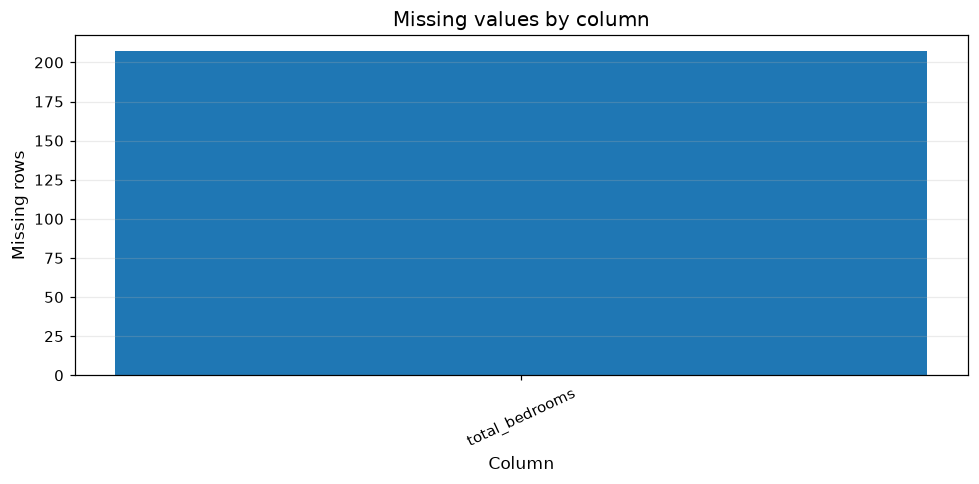

In [4]:
missing_counts = raw_df.isna().sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.5))
nz = missing_counts[missing_counts > 0]
ax.bar(nz.index, nz.values)
ax.set(title="Missing values by column", xlabel="Column", ylabel="Missing rows")
ax.tick_params(axis="x", rotation=25); ax.grid(axis="y", alpha=.25)
save_figure(fig, "01_missing_values.png")

**Interpretation — Plot 1.** The plot isolates the incomplete field and shows that missingness is limited to a single predictor. Since the target is complete, all 20,640 rows remain eligible for regression. Median imputation is carried out within the pipeline so the held-out test set does not influence the imputation statistic.

## 3. Target-variable distribution

### Plot 2 — Target histogram and boxplot

The target is right-skewed, with a long high-value tail and a visible upper ceiling. Exactly 965 rows (about 4.68%) are `$500,001`. This concentration is consistent with a top-coded ceiling in the supplied target values; it is not evidence that all those block groups have identical underlying values. The ceiling limits what a model can learn about the most expensive areas.

/var/folders/b1/wmyxyb614r97qjky96lyz22r0000gn/T/ipykernel_13758/784972343.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(raw_df[TARGET], vert=True, patch_artist=True)


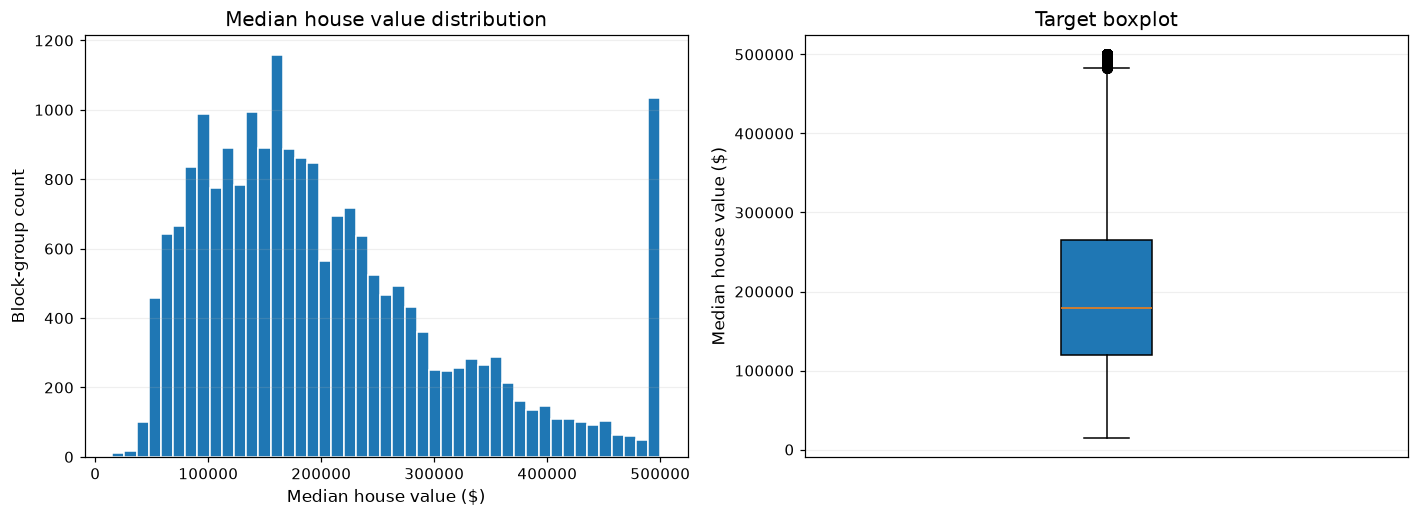

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].hist(raw_df[TARGET], bins=45, edgecolor="white")
axes[0].set(title="Median house value distribution", xlabel="Median house value ($)", ylabel="Block-group count")
axes[0].grid(axis="y", alpha=.2)
axes[1].boxplot(raw_df[TARGET], vert=True, patch_artist=True)
axes[1].set(title="Target boxplot", ylabel="Median house value ($)")
axes[1].tick_params(axis="x", bottom=False, labelbottom=False); axes[1].grid(axis="y", alpha=.2)
save_figure(fig, "02_target_distribution_boxplot.png")

**Interpretation — Plot 2.** Most block-group median values are below the maximum, with fewer observations in the upper tail. The boxplot highlights the spread and high-value extremes. Because the target is capped, predictions in the most expensive areas may be biased downward relative to uncapped underlying values. RMSE/MAE therefore describe performance against the recorded target, not unobserved true prices.

## 4. Numerical predictor distributions

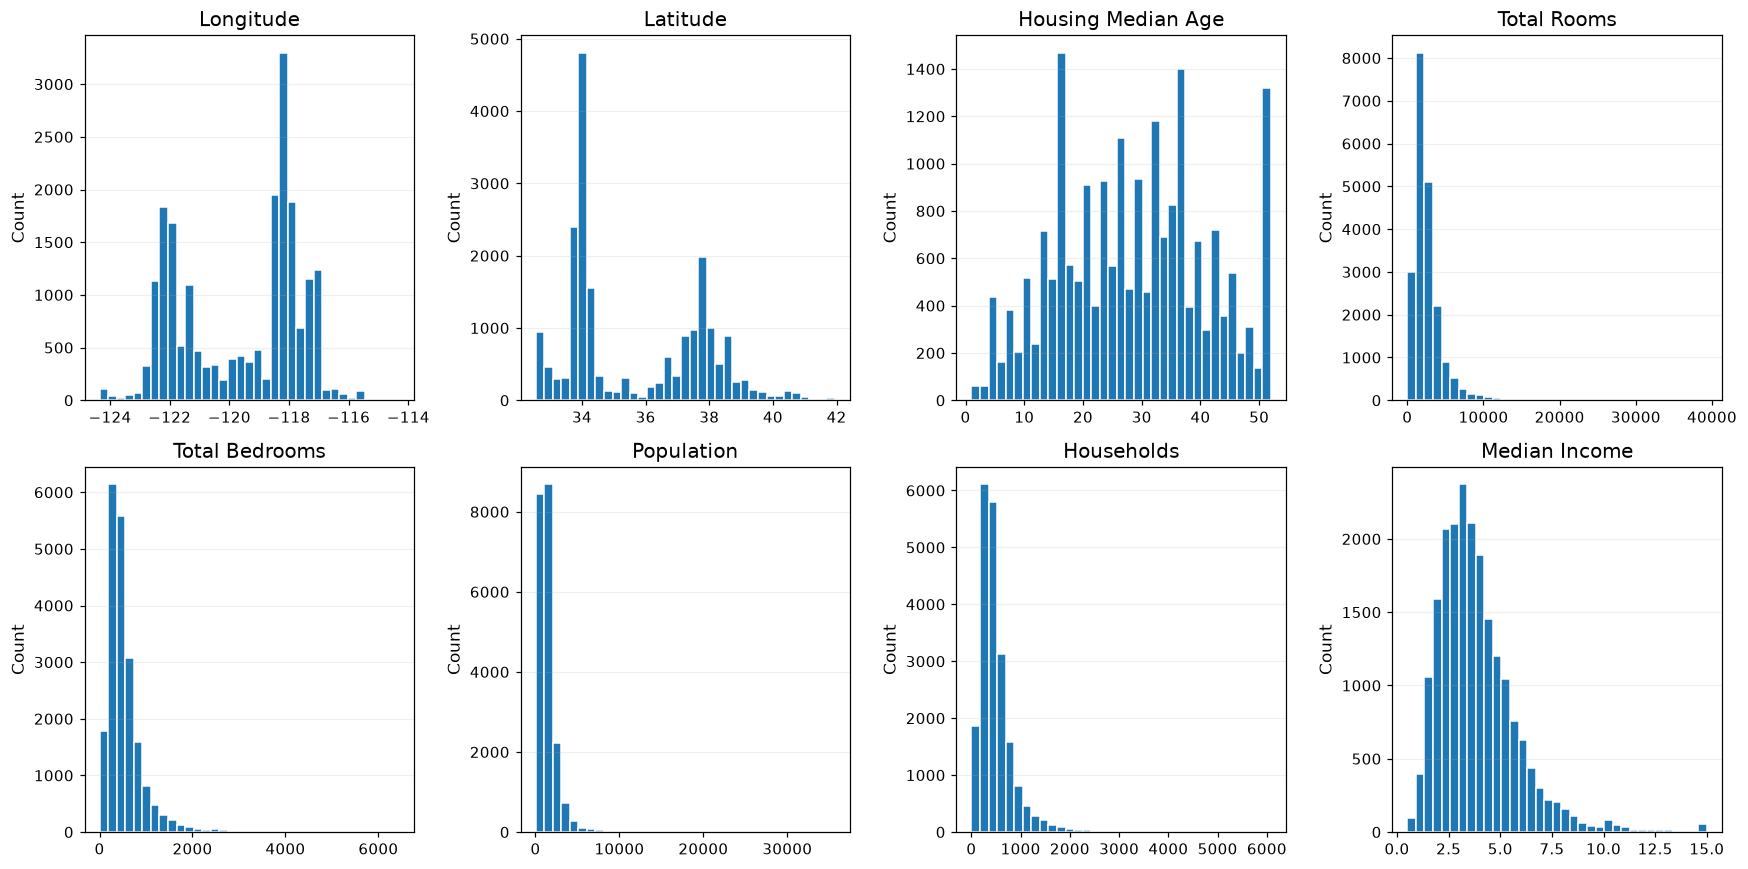

In [6]:
original_numeric = raw_df.select_dtypes(include="number").drop(columns=[TARGET]).columns
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, column in zip(axes.flat, original_numeric):
    ax.hist(raw_df[column].dropna(), bins=35, edgecolor="white")
    ax.set_title(column.replace("_", " ").title())
    ax.set_ylabel("Count"); ax.grid(axis="y", alpha=.2)
save_figure(fig, "03_numeric_feature_distributions.png")

### Interpretation — Plot 3. Numeric feature distributions

The count predictors (`total_rooms`, `total_bedrooms`, `population`, `households`) have long right tails, which means a small number of block groups are much larger than typical ones. `median_income` is also right-skewed. These differences in scale justify standardization, while the aggregate nature of the counts motivates household/person-normalized ratios. Longitude and latitude encode spatial position rather than ordinary physical magnitudes.

## 5. Categorical predictor distribution

,row_count
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


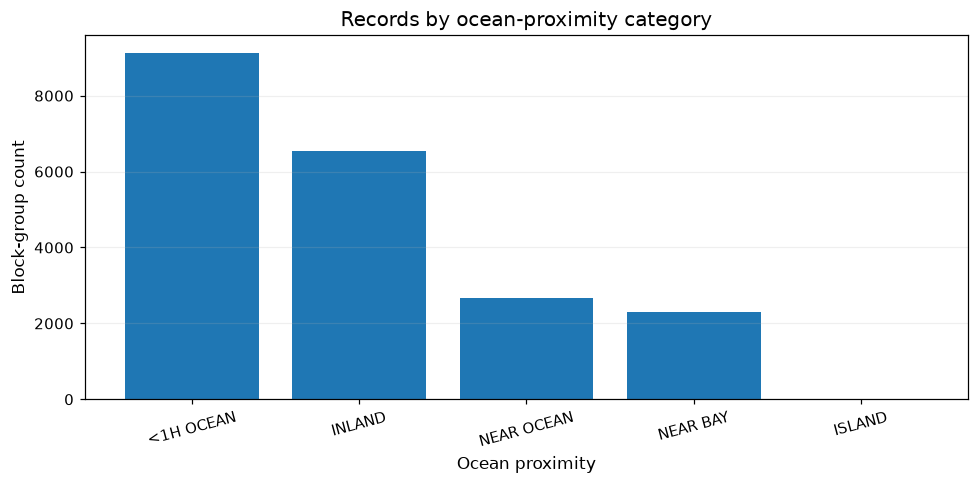

In [7]:
category_counts = raw_df["ocean_proximity"].value_counts()
display(category_counts.to_frame("row_count"))
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(category_counts.index, category_counts.values)
ax.set(title="Records by ocean-proximity category", xlabel="Ocean proximity", ylabel="Block-group count")
ax.tick_params(axis="x", rotation=15); ax.grid(axis="y", alpha=.2)
save_figure(fig, "04_ocean_proximity_counts.png")

### Interpretation — Plot 4. Ocean-proximity counts

`<1H OCEAN` and `INLAND` dominate the sample, while `ISLAND` has only five records. The category imbalance means the `ISLAND` coefficient is weakly supported and should be interpreted cautiously. One-hot encoding preserves the categories without imposing an artificial numeric order; `handle_unknown="ignore"` also makes prediction robust to an unseen category.

## 6. Geographic structure

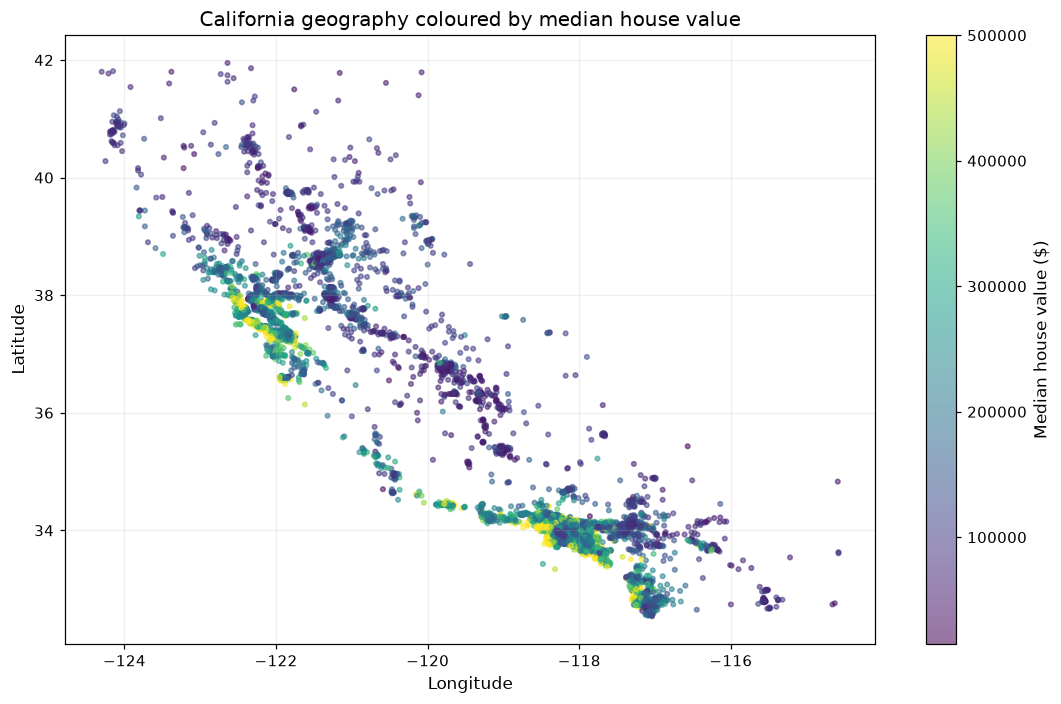

In [8]:
geo_sample = raw_df.sample(n=min(8000, len(raw_df)), random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(10, 6.5))
points = ax.scatter(geo_sample["longitude"], geo_sample["latitude"],
                    c=geo_sample[TARGET], cmap="viridis", s=9, alpha=.55)
fig.colorbar(points, ax=ax, label="Median house value ($)")
ax.set(title="California geography coloured by median house value",
       xlabel="Longitude", ylabel="Latitude")
ax.grid(alpha=.2)
save_figure(fig, "05_geographic_house_value.png")

### Interpretation — Plot 5. Geographic distribution

The point cloud shows spatial clustering: higher recorded values appear in some coastal and metropolitan regions, while many inland regions have lower medians. This supports retaining location coordinates and ocean proximity. The plot is descriptive and does not prove coastal proximity causes higher values; income, density, amenities, supply, and omitted local factors may be involved.

The modelling split is random, so neighbouring block groups may appear in both train and test partitions. The reported score therefore measures interpolation within this dataset more than transfer to a completely unseen geographic region.

## 7. Correlation and multicollinearity

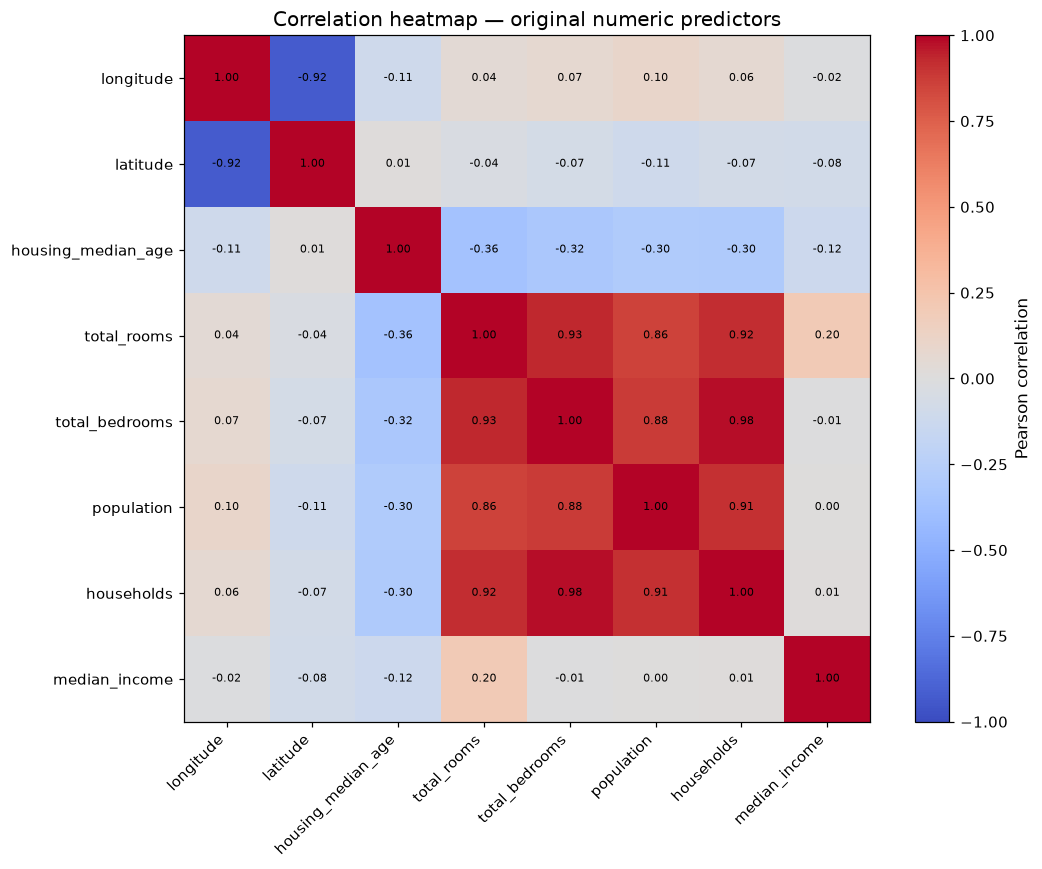

,absolute_correlation,correlation,feature_1,feature_2
0,0.980,0.980,total_bedrooms,households
1,0.930,0.930,total_rooms,total_bedrooms
2,0.925,-0.925,longitude,latitude
3,0.918,0.918,total_rooms,households
4,0.907,0.907,population,households
5,0.878,0.878,total_bedrooms,population
6,0.857,0.857,total_rooms,population
7,0.361,-0.361,housing_median_age,total_rooms


In [9]:
numeric_corr = raw_df.select_dtypes(include="number").drop(columns=[TARGET]).corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(numeric_corr, cmap="coolwarm", vmin=-1, vmax=1)
fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_xticks(range(len(numeric_corr.columns)), numeric_corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(numeric_corr.columns)), numeric_corr.columns)
ax.set_title("Correlation heatmap — original numeric predictors")
for i in range(len(numeric_corr.columns)):
    for j in range(len(numeric_corr.columns)):
        ax.text(j, i, f"{numeric_corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
save_figure(fig, "06_numeric_correlation_heatmap.png")

pairs = []
for i, first in enumerate(numeric_corr.columns):
    for second in numeric_corr.columns[i+1:]:
        pairs.append((abs(numeric_corr.loc[first, second]), numeric_corr.loc[first, second], first, second))
top_pairs = sorted(pairs, reverse=True)[:8]
display(pd.DataFrame(top_pairs, columns=["absolute_correlation", "correlation", "feature_1", "feature_2"]))

### Interpretation — Plot 6. Correlation heatmap

The strongest pairwise correlations include `total_bedrooms` with `households` (about **0.98**), `total_rooms` with `total_bedrooms` (about **0.93**), and `longitude` with `latitude` (about **−0.92**). These predictors carry overlapping information, which can make OLS coefficients unstable even if test predictions remain useful.

We retain the original predictors and compare OLS with Ridge and Lasso rather than deleting features based only on pairwise correlation. Ridge shrinks correlated coefficients jointly; Lasso can set some to zero. A correlation heatmap is only a pairwise linear diagnostic, not a complete multicollinearity test.

## 8. Feature engineering and leakage control

The task requests interaction features. Alongside original columns, we add `rooms_per_household`, `bedrooms_per_room`, `population_per_household`, `rooms_per_person`, `income_x_rooms_per_household`, `income_x_housing_age`, and `latitude_x_longitude`. Safe denominators convert zero denominators to missing values, which are subsequently imputed by the training-fitted pipeline.

These are deterministic row-level calculations and do not use the target. Imputation, scaling, and categorical encoding are learned only inside each training fold.

In [10]:
featured_df = engineer_features(raw_df)
numeric_features, categorical_features = get_feature_columns(featured_df)
display(featured_df[[
    "rooms_per_household", "bedrooms_per_room", "population_per_household",
    "rooms_per_person", "income_x_rooms_per_household",
    "income_x_housing_age", "latitude_x_longitude"
]].describe().T)
print("Numeric predictors:", len(numeric_features))
print("Categorical predictors:", categorical_features)

,count,mean,std,min,25%,50%,75%,max
rooms_per_household,"20,640.000",5.429,2.474,0.846,4.441,5.229,6.052,141.909
bedrooms_per_room,"20,433.000",0.213,0.058,0.100,0.175,0.203,0.240,1.000
population_per_household,"20,640.000",3.071,10.386,0.692,2.430,2.818,3.282,"1,243.333"
rooms_per_person,"20,640.000",1.977,1.146,0.003,1.522,1.938,2.296,55.222
income_x_rooms_per_household,"20,640.000",22.550,17.923,0.857,11.687,18.022,27.864,612.967
income_x_housing_age,"20,640.000",108.008,74.386,1.625,57.997,92.503,140.105,780.005
latitude_x_longitude,"20,640.000","-4,264.448",323.904,"-5,207.673","-4,601.026","-4,060.279","-4,004.350","-3,753.968"


Numeric predictors: 15
Categorical predictors: ['ocean_proximity']


**Feature-engineering interpretation.** Per-household/per-person ratios normalize aggregate counts by group size. The income interaction terms allow the fitted linear model to represent selected combined effects (for example, income acting differently across housing-age contexts). Such features may add information or redundancy; their usefulness is assessed on held-out data rather than assumed in advance.

## 9. Train/test split and preprocessing design

We use an 80/20 random split (`random_state=42`). Numeric predictors are median-imputed and standardized. `ocean_proximity` is imputed with the most frequent category and one-hot encoded. The same preprocessor is attached to OLS, Ridge, and Lasso to keep the comparison controlled.

Ridge and Lasso are tuned using 3-fold `GridSearchCV` with negative RMSE as the selection score. The test partition is not used for alpha selection. The Ridge grid is `[0.1, 1, 10, 100]`; the Lasso grid is `[100, 300, 1000, 3000]`. These explicit candidate grids are practical starting points, not a guarantee of the global optimum.

In [11]:
X = featured_df.drop(columns=[TARGET])
y = featured_df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(f"Training rows: {len(X_train):,}")
print(f"Test rows: {len(X_test):,}")
print(f"Training/test ratio: {len(X_train)/len(X):.0%}/{len(X_test)/len(X):.0%}")

Training rows: 16,512
Test rows: 4,128
Training/test ratio: 80%/20%


## 10. Fit OLS, Ridge, and Lasso

In [12]:
with warnings.catch_warnings(record=True) as fit_warnings:
    warnings.simplefilter("always")
    experiment = run_experiment(
        dataset_path=DATA_PATH,
        output_dir=OUTPUT_DIR,
        random_state=RANDOM_STATE,
        cv=CV_FOLDS,
    )
for warning in fit_warnings:
    print(f"{type(warning.message).__name__}: {warning.message}")

comparison = experiment["comparison"]
tuning_results = experiment["tuning"]
predictions = experiment["predictions"]
best_name = experiment["best_model_name"]
print("Best model by held-out RMSE:", best_name)
display(comparison.style.format({
    "RMSE": "${:,.2f}", "MAE": "${:,.2f}", "R2": "{:.4f}",
    "best_alpha": "{:.3g}", "best_cv_rmse": "${:,.2f}"
}))
display(tuning_results)

Best model by held-out RMSE: OLS


,model,RMSE,MAE,R2,best_alpha,best_cv_rmse
0,OLS,"$67,010.38","$48,122.06",0.6573,nan,$nan
1,Ridge,"$67,027.03","$48,138.93",0.6572,0.1,"$66,970.44"
2,Lasso,"$67,527.05","$48,300.72",0.6520,300,"$67,108.56"


,model,alpha,mean_cv_rmse,std_cv_rmse,mean_train_rmse
0,Ridge,0.100,"66,970.443","1,727.489","65,968.966"
1,Ridge,1.000,"67,078.517","1,656.562","66,094.164"
2,Ridge,10.000,"67,181.296","1,627.560","66,217.342"
3,Ridge,100.000,"67,192.375","1,596.852","66,345.356"
4,Lasso,100.000,"67,154.576","1,605.327","66,257.937"
5,Lasso,300.000,"67,108.558","1,578.300","66,348.639"
6,Lasso,"1,000.000","67,416.194","1,427.168","66,960.639"
7,Lasso,"3,000.000","69,590.687",670.912,"69,280.001"


### Initial numerical interpretation

On the fixed 80/20 split, OLS achieves RMSE of approximately **$67,010**, MAE of **$48,122**, and R² of **0.6573**. Ridge is almost tied (RMSE about **$67,027**, R² **0.6572**). Lasso is somewhat higher (RMSE about **$67,528**, R² **0.6520**). OLS is the best model by test RMSE in this run, but the OLS/Ridge difference is very small. Regularization may still be useful for coefficient stability even when it does not improve this particular split's prediction error.

## 11. Model metric comparison

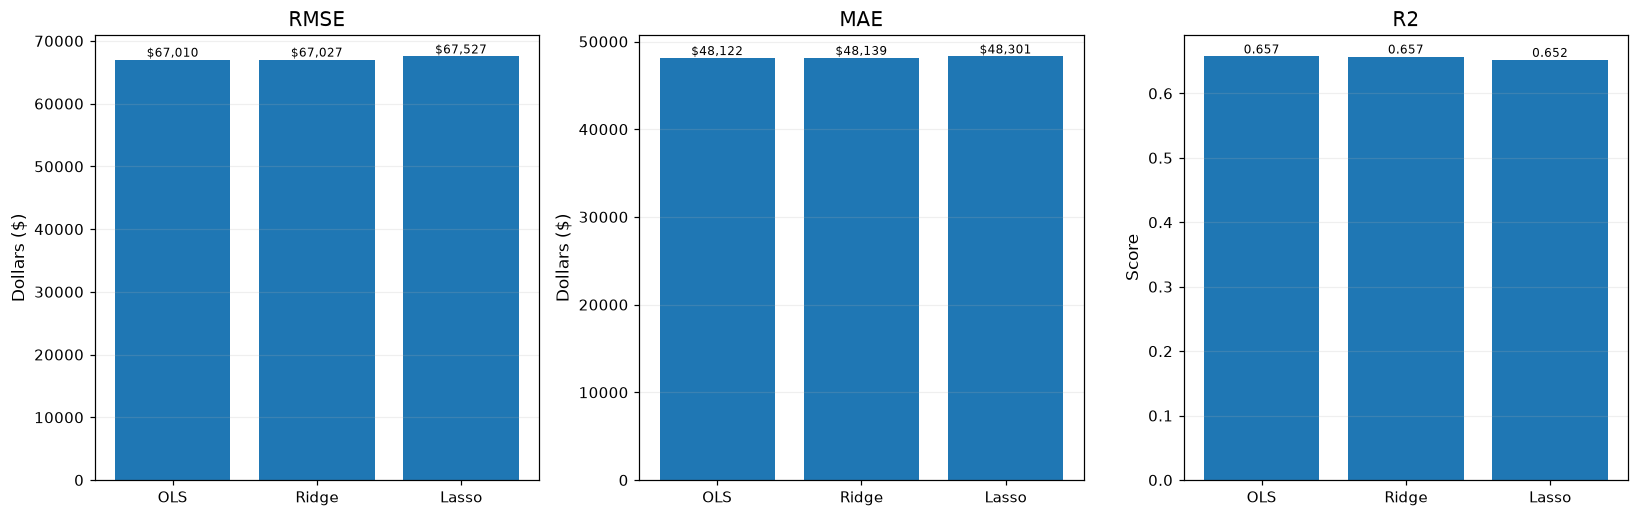

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, metric in zip(axes, ["RMSE", "MAE", "R2"]):
    values = comparison.set_index("model")[metric]
    ax.bar(values.index, values.values)
    ax.set_title(metric)
    ax.set_ylabel("Score" if metric == "R2" else "Dollars ($)")
    ax.grid(axis="y", alpha=.2)
    for i, value in enumerate(values.values):
        ax.text(i, value, f"{value:.3f}" if metric == "R2" else f"${value:,.0f}",
                ha="center", va="bottom", fontsize=8)
save_figure(fig, "07_model_metric_comparison.png")

### Interpretation — Plot 7. Model metric comparison

Lower RMSE and MAE are better; higher R² is better. OLS slightly outperforms Ridge on all three metrics in this split, while Lasso is weaker. OLS/Ridge differ by only about `$17` in RMSE and `0.0002` in R², so the practical predictive gap is negligible. RMSE is larger than MAE, indicating that a subset of test cases has relatively large errors. R² near 0.66 means the models explain roughly two-thirds of the variance in recorded test values; substantial variation remains unexplained.

## 12. GridSearchCV alpha curves

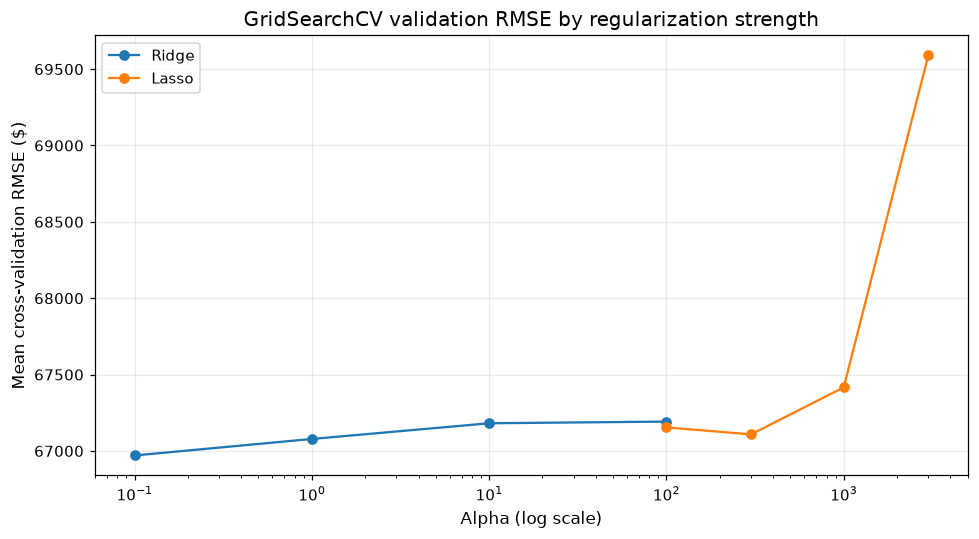

model,Lasso,Ridge
alpha,,
0.100,NaN,"66,970.443"
1.000,NaN,"67,078.517"
10.000,NaN,"67,181.296"
100.000,"67,154.576","67,192.375"
300.000,"67,108.558",NaN
"1,000.000","67,416.194",NaN
"3,000.000","69,590.687",NaN


In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
for model_name in ["Ridge", "Lasso"]:
    subset = tuning_results[tuning_results["model"] == model_name].sort_values("alpha")
    ax.plot(subset["alpha"], subset["mean_cv_rmse"], marker="o", label=model_name)
ax.set_xscale("log")
ax.set(title="GridSearchCV validation RMSE by regularization strength",
       xlabel="Alpha (log scale)", ylabel="Mean cross-validation RMSE ($)")
ax.legend(); ax.grid(alpha=.25)
save_figure(fig, "08_alpha_search_cv_rmse.png")
display(tuning_results.pivot(index="alpha", columns="model", values="mean_cv_rmse"))

### Interpretation — Plot 8. Alpha selection

Ridge selects **alpha = 0.1**, the smallest candidate in its grid, suggesting that stronger Ridge shrinkage did not improve the CV score within the search range. Lasso selects **alpha = 300**; stronger penalties eventually increase validation error, consistent with excessive shrinkage/underfitting. The selected values are optimal only among the stated candidates and this three-fold CV design. A denser grid or repeated/spatial validation could change them.

## 13. Predicted versus actual values

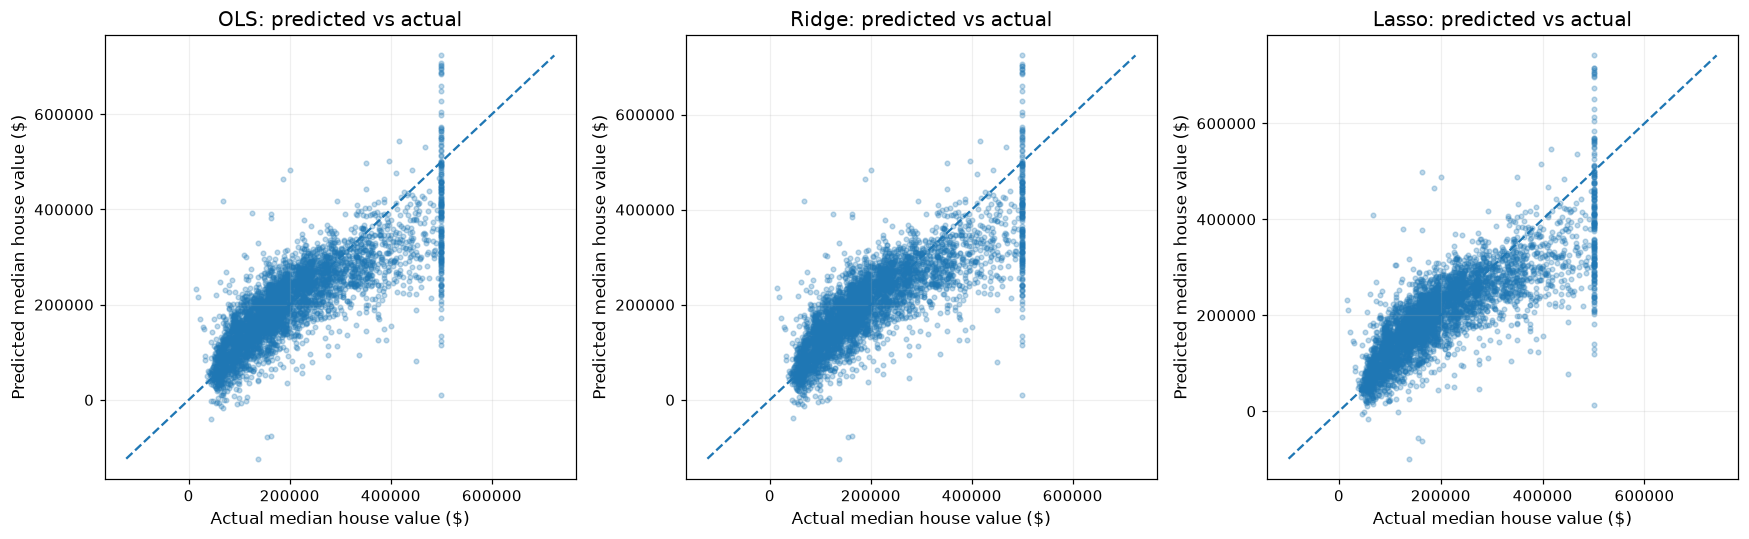

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, model_name in zip(axes, ["OLS", "Ridge", "Lasso"]):
    yhat = predictions[model_name].to_numpy()
    ax.scatter(y_test, yhat, s=9, alpha=.28)
    low, high = min(y_test.min(), yhat.min()), max(y_test.max(), yhat.max())
    ax.plot([low, high], [low, high], linestyle="--", linewidth=1.5)
    ax.set(title=f"{model_name}: predicted vs actual",
           xlabel="Actual median house value ($)", ylabel="Predicted median house value ($)")
    ax.grid(alpha=.2)
save_figure(fig, "09_predicted_vs_actual.png")

### Interpretation — Plot 9. Predicted versus actual

All three panels follow the upward diagonal, showing that the predictors contain useful signal. The broad scatter around the reference line is consistent with RMSE around `$67k`. Predictions are less precise near the high end, where observations are sparser and the recorded target is capped at `$500,001`. OLS and Ridge look similar, in line with their nearly identical metrics. These predictions are block-group medians, not estimates for a specific property.

## 14. Residual distribution

,model,mean_residual,median_residual,residual_std
0,OLS,$873.25,"$-8,028.85","$67,012.81"
1,Ridge,$879.88,"$-8,006.27","$67,029.38"
2,Lasso,$818.41,"$-8,778.99","$67,530.27"


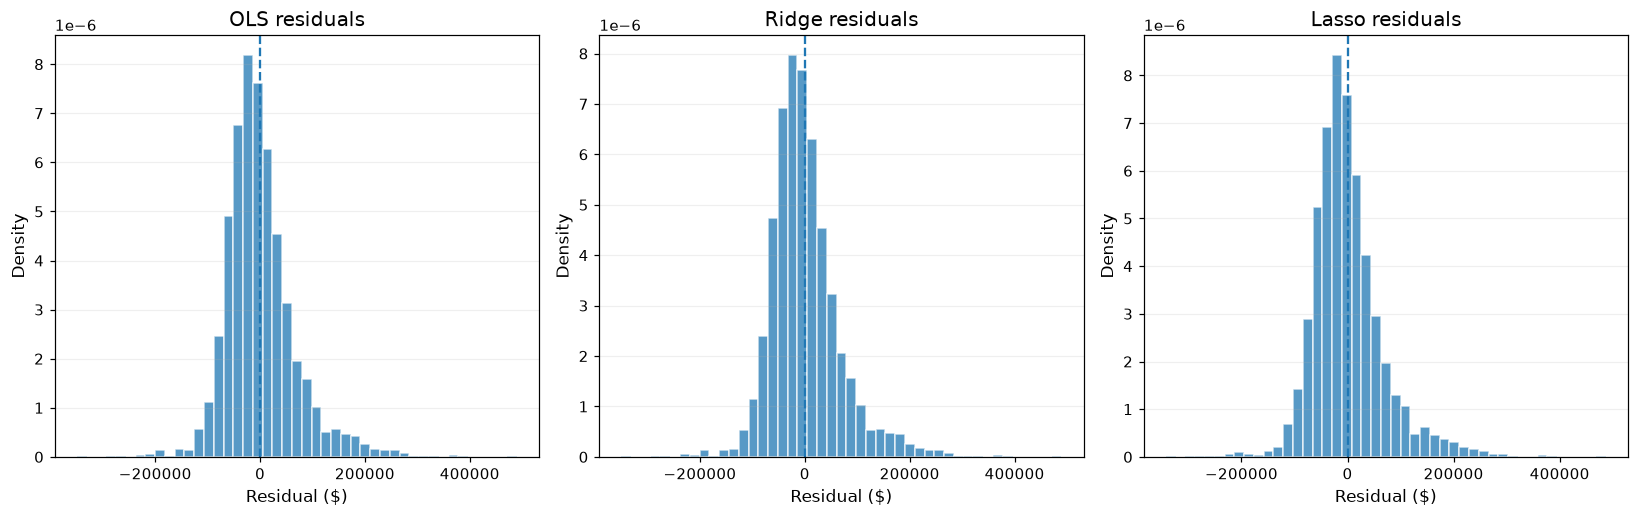

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
residual_summary = []
for ax, model_name in zip(axes, ["OLS", "Ridge", "Lasso"]):
    residual = y_test.to_numpy() - predictions[model_name].to_numpy()
    ax.hist(residual, bins=45, density=True, alpha=.75, edgecolor="white")
    ax.axvline(0, linestyle="--", linewidth=1.5)
    ax.set(title=f"{model_name} residuals", xlabel="Residual ($)", ylabel="Density")
    ax.grid(axis="y", alpha=.2)
    residual_summary.append({
        "model": model_name, "mean_residual": residual.mean(),
        "median_residual": np.median(residual), "residual_std": residual.std(ddof=1)
    })
display(pd.DataFrame(residual_summary).style.format({
    "mean_residual": "${:,.2f}", "median_residual": "${:,.2f}",
    "residual_std": "${:,.2f}"
}))
save_figure(fig, "10_residual_distributions.png")

### Interpretation — Plot 10. Residual distributions

Residual is actual minus predicted: positive means underprediction, negative means overprediction. Inspect whether each distribution is centred near zero, whether it is skewed, and how heavy its tails are. Broad tails indicate block groups with large missed values. A distribution near zero suggests limited overall additive bias but does not prove independent or constant-variance errors. OLS and Ridge are expected to appear similar given their close scores; compare the residual summary table for numerical bias and spread.

## 15. Residuals versus predicted values

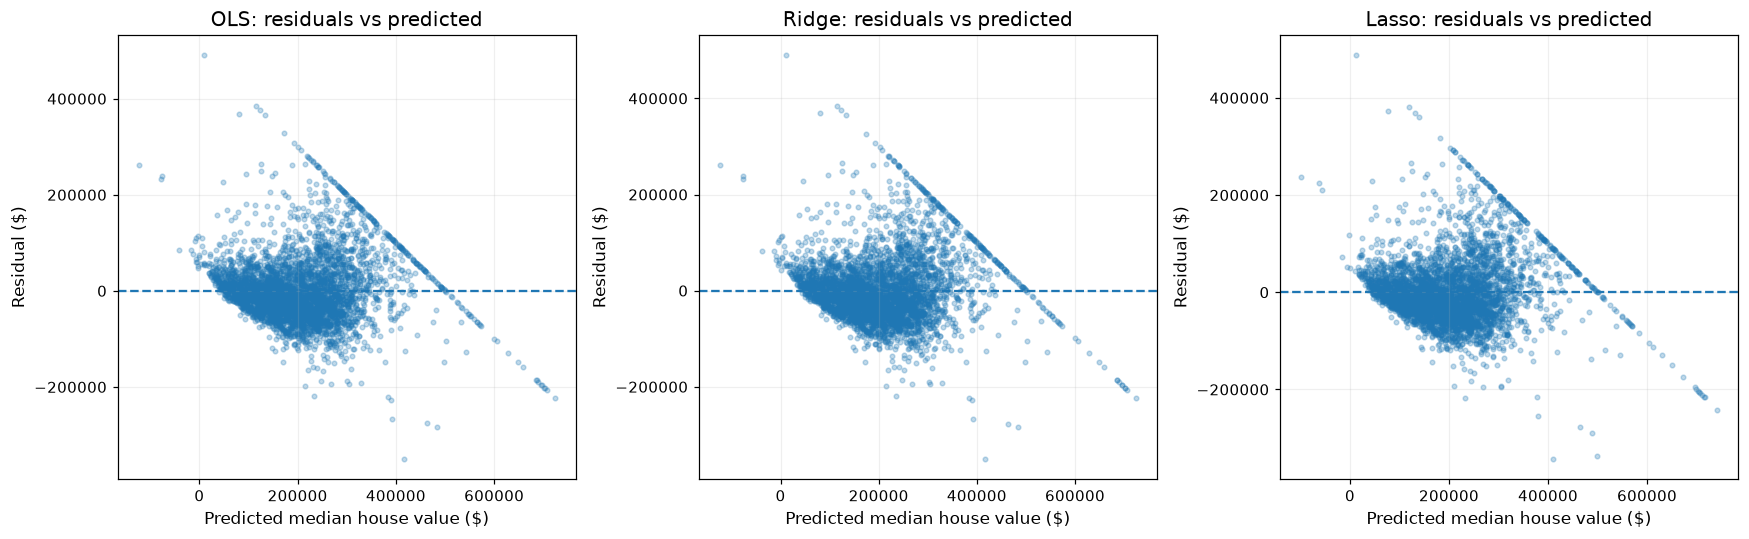

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, model_name in zip(axes, ["OLS", "Ridge", "Lasso"]):
    yhat = predictions[model_name].to_numpy()
    residual = y_test.to_numpy() - yhat
    ax.scatter(yhat, residual, s=9, alpha=.28)
    ax.axhline(0, linestyle="--", linewidth=1.5)
    ax.set(title=f"{model_name}: residuals vs predicted",
           xlabel="Predicted median house value ($)", ylabel="Residual ($)")
    ax.grid(alpha=.2)
save_figure(fig, "11_residuals_vs_predicted.png")

### Interpretation — Plot 11. Residuals versus predicted

A horizontal cloud around zero is the desired pattern. Curvature would suggest a missing nonlinear structure; a funnel-like widening would suggest non-constant residual variance; clusters can indicate omitted segments or geography. The clear descending streak at the high-prediction end is especially informative: many actual targets are fixed at the `$500,001` ceiling, while their predictions vary above that value. Since residual = actual − predicted, these capped records form a descending line as predicted values increase. This is a direct visual consequence of the ceiling, not an ordinary random residual cloud. The pattern and any widening elsewhere show that the linear specification does not capture all structure.

## 16. Coefficient magnitudes

,feature,coefficient,absolute_coefficient
14,numeric__latitude_x_longitude,"770,957.815","770,957.815"
1,numeric__latitude,"561,105.474","561,105.474"
0,numeric__longitude,"-219,258.166","219,258.166"
17,categorical__ocean_proximity_ISLAND,"114,416.801","114,416.801"
7,numeric__median_income,"79,394.476","79,394.476"
16,categorical__ocean_proximity_INLAND,"-59,416.009","59,416.009"
11,numeric__rooms_per_person,"31,818.242","31,818.242"
5,numeric__population,"-25,795.739","25,795.739"
18,categorical__ocean_proximity_NEAR BAY,"-23,748.546","23,748.546"
15,categorical__ocean_proximity_<1H OCEAN,"-18,854.173","18,854.173"


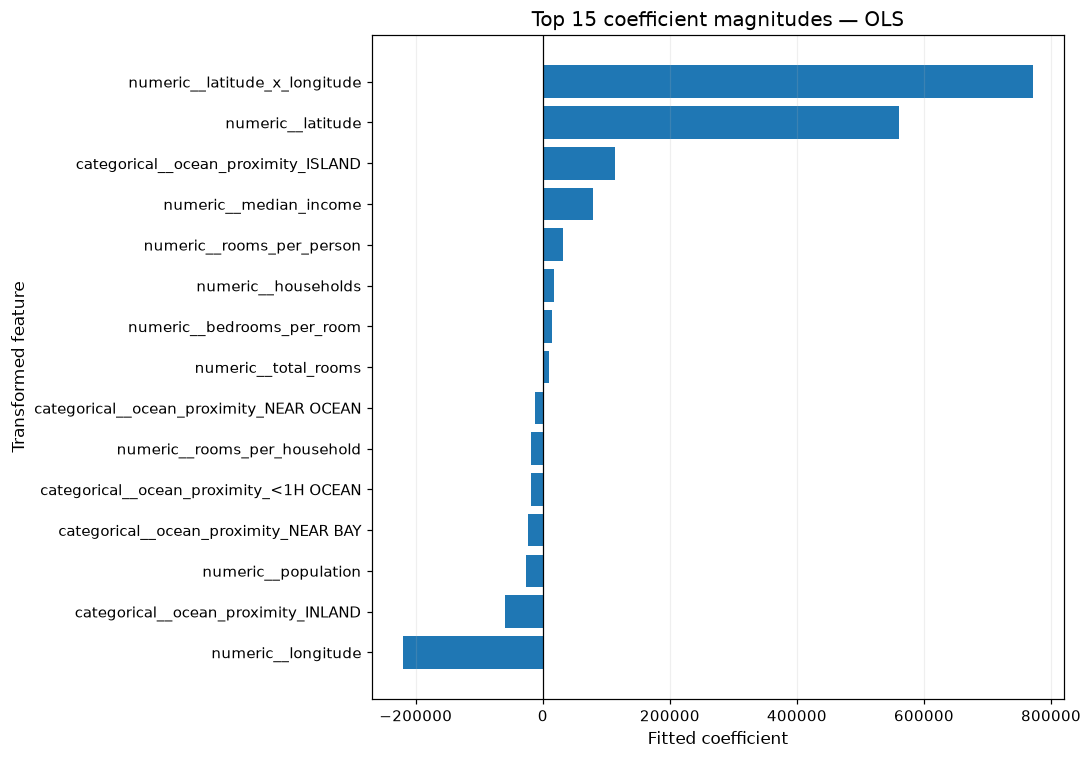

In [18]:
best_model = experiment["best_model"]
preprocessor = best_model.named_steps["preprocessor"]
feature_names = preprocessor.get_feature_names_out()
coef = np.asarray(best_model.named_steps["regressor"].coef_).ravel()
coef_table = pd.DataFrame({"feature": feature_names, "coefficient": coef})
coef_table["absolute_coefficient"] = coef_table["coefficient"].abs()
top_coef = coef_table.sort_values("absolute_coefficient", ascending=False).head(15).sort_values("coefficient")
display(top_coef.sort_values("absolute_coefficient", ascending=False))
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_coef["feature"], top_coef["coefficient"])
ax.axvline(0, color="black", linewidth=.8)
ax.set(title=f"Top 15 coefficient magnitudes — {best_name}",
       xlabel="Fitted coefficient", ylabel="Transformed feature")
ax.grid(axis="x", alpha=.2)
save_figure(fig, "12_best_model_coefficients.png")

### Interpretation — Plot 12. Coefficients

Numeric features are standardized, so their coefficients refer to a one-standard-deviation change in the input. One-hot indicators remain binary and are not standardized, so coefficient size comparisons between these groups need care. Large absolute coefficients indicate greater fitted sensitivity conditional on the other predictors, not causal impact. Strong correlations can redistribute weight among related predictors, particularly in OLS.

## 17. Lasso sparsity

,model,coefficient_count,zero_coefficients,nonzero_coefficients
0,OLS,20,0,20
1,Ridge,20,0,20
2,Lasso,20,3,17


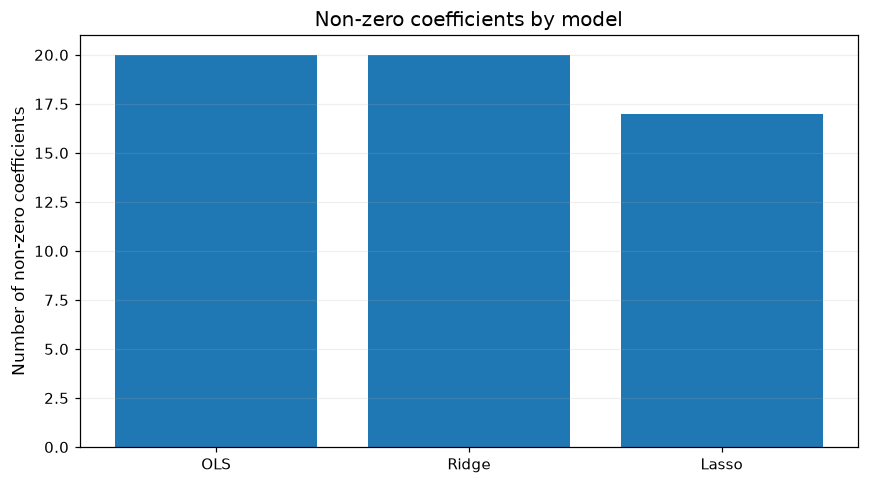

In [19]:
sparsity_rows = []
for model_name in ["OLS", "Ridge", "Lasso"]:
    values = np.asarray(experiment["models"][model_name].named_steps["regressor"].coef_).ravel()
    zero_count = int(np.isclose(values, 0.0, atol=1e-8).sum())
    sparsity_rows.append({
        "model": model_name, "coefficient_count": len(values),
        "zero_coefficients": zero_count, "nonzero_coefficients": len(values)-zero_count
    })
sparsity = pd.DataFrame(sparsity_rows)
display(sparsity)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(sparsity["model"], sparsity["nonzero_coefficients"])
ax.set(title="Non-zero coefficients by model", ylabel="Number of non-zero coefficients")
ax.grid(axis="y", alpha=.2)
save_figure(fig, "13_nonzero_coefficients.png")

### Interpretation — Plot 13. Non-zero coefficients

Lasso can set coefficients exactly to zero, unlike Ridge's usual continuous shrinkage. A lower non-zero count indicates a sparser fitted representation, not necessarily a better model: Lasso does not win on test RMSE in this run. When predictors are correlated, Lasso may keep one and suppress another, and that selection can vary across samples. The zero count is not a definitive ranking of causal importance.

## 18. Final model assessment, limitations, and reproducibility

The best model by held-out RMSE is selected for this run. The result is specific to the supplied CSV, fixed random split, engineered features, and chosen alpha grids.

In [20]:
best_row = comparison.iloc[0]
print(f"Best model by test RMSE: {best_row['model']}")
print(f"RMSE: ${best_row['RMSE']:,.2f}")
print(f"MAE:  ${best_row['MAE']:,.2f}")
print(f"R2:   {best_row['R2']:.4f}")
print(f"Training rows: {len(experiment['X_train']):,}; test rows: {len(experiment['X_test']):,}")
print(f"Missing total_bedrooms: {int(raw_df['total_bedrooms'].isna().sum())}")
print(f"Target-ceiling rows: {int((raw_df[TARGET] == raw_df[TARGET].max()).sum())}")
print("Artifacts written to:", OUTPUT_DIR)

Best model by test RMSE: OLS
RMSE: $67,010.38
MAE:  $48,122.06
R2:   0.6573
Training rows: 16,512; test rows: 4,128
Missing total_bedrooms: 207
Target-ceiling rows: 965
Artifacts written to: /Users/subhankarbiswas/Datheon_Machine_Learning_&_Data_Science_Internship/california-housing-ridge-lasso/outputs


### Main conclusions

- OLS yields the lowest test RMSE on this fixed split; Ridge is nearly tied; Lasso is somewhat weaker.
- Multicollinearity is visible among aggregate count predictors, especially bedrooms/households and rooms/bedrooms. Regularization offers a coefficient-stability trade-off.
- Grid search selects Ridge alpha = 0.1 and Lasso alpha = 300 from the candidate grids.
- Engineered ratios/interactions provide interpretable additional predictors, but the overall R² near 0.66 indicates substantial unexplained variation.

### Limitations

1. 965 target rows (about 4.68%) are capped at `$500,001`; underlying values above this ceiling are unobserved.
2. Correlated predictors complicate coefficient-level interpretation.
3. `ISLAND` has only five observations.
4. Random splitting can place geographically nearby groups in both train and test sets, so results may overstate transfer to new regions.
5. The dataset measures block groups, not individual homes.
6. Property condition, school quality, local employment, zoning, and temporal market changes are absent.

### Further work

Consider repeated and spatially grouped validation, richer nonlinear features, and explicit treatment of the capped target. Such extensions should be reported as separate experiments, rather than quietly replacing this requested OLS/Ridge/Lasso baseline.

### Reproduce

From the repository root:

```bash
python -m pip install -r requirements.txt
jupyter notebook notebooks/real_estate_housing_price_prediction.ipynb
```

The pipeline exports `model_comparison.csv`, `hyperparameter_search.csv`, `test_predictions.csv`, `best_model_coefficients.csv`, and all PNGs in `outputs/figures/`. The GitHub Actions workflow executes the notebook and runs the tests.